# Looking-While-Listening: target gaze heatmaps

Python reproduction of `gaze_location_lwl.R`, using the root `gaze_density_by_target.png` as the visual reference. Run all cells to see an overview, a selectable target, and gaze scatter plots inline.

**Kernel:** select the existing **davinci** Python environment:
`/data/kushinm/miniconda3/envs/davinci/bin/python` (Python 3.10.16).
All dependencies are already installed; verified versions are in `requirements.txt`.

Only aggregate counts and plots are displayed. Raw participant records and identifiers should stay out of saved notebook outputs.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Rectangle
from PIL import Image as PILImage
from IPython.display import display, Image as DisplayImage

REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "gaze_location_lwl.R").is_file() and (p / "stim_images").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Start the notebook from the repository root or notebooks/.")

print(f"Python {sys.version.split()[0]}: {sys.executable}")
display(pd.Series(
    {name: importlib.metadata.version(name)
     for name in ("numpy", "pandas", "matplotlib", "Pillow", "ipykernel")},
    name="Installed version",
).to_frame())

Python 3.10.16: /data/kushinm/miniconda3/envs/davinci/bin/python


,Installed version
numpy,2.0.1
pandas,2.2.3
matplotlib,3.10.0
Pillow,11.1.0
ipykernel,6.29.5


## Settings

Defaults match the R analysis: 3550–5050 ms inclusive; both conditions pooled; only tracked, non-interpolated target looks enter the heatmaps. Edit these settings and rerun subsequent cells to explore a different window or a single condition.

The geometry remains the original analysis assumption. This notebook preserves its increasing-Y display convention and upright images. It does **not** reverse Y, mirror images, center the image in the AOI, or crop away the AOI buffer.

In [2]:
DATA_PATH = REPO_ROOT / "full_lwl_aois_Aug3.csv"
IMAGE_DIR = REPO_ROOT / "stim_images"
OUTPUT_DIR = REPO_ROOT / "outputs" / "python_gaze_inspection"

TIME_WINDOW_MS = (3550, 5050)
CONDITIONS = ("Unrelated", "Related")
TARGET_ORDER = ("apple", "banana", "bathtub", "carrots", "comb", "peas", "potty", "toothbrush")
TARGET_TO_INSPECT = "comb"
GRID_SIZE = 100
HEATMAP_ALPHA = 0.75
SAVE_FIGURES = True
SHOW_EACH_TARGET = False
SHOW_R_REFERENCE = True

X_SHIFT = 1200.0
# Tuples are (xmin, xmax, ymin, ymax), in the original plotted coordinates.
STIM_BOX = (110.0, 610.0, 290.0, 790.0)  # 500 x 500 image
AOI_BOX = (0.0, 620.0, 190.0, 810.0)     # 620 x 620 left AOI

if SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert TIME_WINDOW_MS[0] <= TIME_WINDOW_MS[1]
assert CONDITIONS and set(CONDITIONS) <= {"Unrelated", "Related"}
assert GRID_SIZE >= 2

## Load and apply the same sample filters

The CDI file is not used here. We read only the columns needed for the gaze maps and do not display raw rows. `LookAOI` supplies the original AOI classification: after translating right-side targets left, some valid target looks can lie outside the drawn left AOI. We retain them, as the R script does.

In [3]:
columns = [
    "Condition", "TargetImage", "TargetObjectPos", "DistracterImage",
    "GazePointXMean", "GazePointYMean", "LookAOI", "isTracked",
    "isInterpolatedFrame", "TimeBinMs",
]
labels = {name: "string" for name in (
    "Condition", "TargetImage", "TargetObjectPos", "DistracterImage", "LookAOI", "isTracked"
)}
gaze = pd.read_csv(DATA_PATH, usecols=columns, dtype=labels)

valid = (
    gaze["GazePointXMean"].notna()
    & gaze["GazePointYMean"].notna()
    & gaze["LookAOI"].isin(["left", "right"])
    & gaze["isTracked"].eq("yes")
    & gaze["isInterpolatedFrame"].eq(0)
    & gaze["TimeBinMs"].between(*TIME_WINDOW_MS, inclusive="both")
    & gaze["Condition"].isin(CONDITIONS)
    & gaze["TargetObjectPos"].isin(["centerLeft", "centerRight"])
)
gaze_clean = gaze.loc[valid].copy()
gaze_clean["TargetAOI"] = gaze_clean["TargetObjectPos"].map(
    {"centerLeft": "left", "centerRight": "right"}
)
gaze_clean["AOIType"] = np.where(
    gaze_clean["LookAOI"].eq(gaze_clean["TargetAOI"]), "Target", "Distractor"
)
gaze_clean["GazePointXMean_norm"] = (
    gaze_clean["GazePointXMean"]
    - np.where(gaze_clean["TargetAOI"].eq("right"), X_SHIFT, 0.0)
)
gaze_clean["Condition"] = pd.Categorical(
    gaze_clean["Condition"], categories=CONDITIONS, ordered=True
)
gaze_clean["AOIType"] = pd.Categorical(
    gaze_clean["AOIType"], categories=["Target", "Distractor"], ordered=True
)
gaze_target = gaze_clean.loc[gaze_clean["AOIType"].eq("Target")].copy()
if gaze_target.empty:
    raise ValueError("No valid target samples remain for these settings.")
unknown = set(gaze_target["TargetImage"].unique()) - set(TARGET_ORDER)
if unknown:
    raise ValueError(f"Unexpected target images: {sorted(unknown)}")
target_names = [t for t in TARGET_ORDER if gaze_target["TargetImage"].eq(t).any()]

sample_counts = (
    gaze_clean.groupby(["TargetImage", "Condition", "AOIType"], observed=True)
    .size().rename("n_samples").reset_index()
)
display(pd.DataFrame({
    "Stage": ["Input samples", "Retained samples in either AOI", "Target samples for heatmaps"],
    "Samples": [len(gaze), len(gaze_clean), len(gaze_target)],
}))
display(sample_counts)
print("Defaults on the supplied data: 391,601 input; 69,015 retained; 43,854 target samples.")

,Stage,Samples
0,Input samples,391601
1,Retained samples in either AOI,69015
2,Target samples for heatmaps,43854


,TargetImage,Condition,AOIType,n_samples
0,apple,Unrelated,Target,2880
1,apple,Unrelated,Distractor,1219
2,apple,Related,Target,3100
3,apple,Related,Distractor,1282
4,banana,Unrelated,Target,2795
5,banana,Unrelated,Distractor,1304
6,banana,Related,Target,2765
7,banana,Related,Distractor,1679
8,bathtub,Unrelated,Target,2272
9,bathtub,Unrelated,Distractor,1427


Defaults on the supplied data: 391,601 input; 69,015 retained; 43,854 target samples.


## Reproduce the R density estimator

`ggplot2::stat_density_2d()` calls `MASS::kde2d()`. That estimator uses a product of one-dimensional Gaussian kernels with separate X and Y bandwidths:

`bandwidth = 1.06 * min(sample SD, IQR / 1.34) * n**(-1/5)`.

R's `bandwidth.nrd()` returns four times this value and `kde2d()` divides it by four again. The implementation below reproduces the net result. R's default quantiles correspond to NumPy's linear quantiles. A covariance-based `gaussian_kde` with its default bandwidth would give a different map.

All targets share the same 100×100 evaluation grid, trained on the pooled target samples plus image/AOI bounds. The density is conditional on retained target looks; it is not a measure of how often infants chose the target. Participants with more retained samples contribute more weight, matching the R analysis.

In [4]:
def r_kde_bandwidth(values):
    """Effective bandwidth from MASS::bandwidth.nrd()/4."""
    values = np.asarray(values, dtype=float)
    if len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("KDE requires at least two finite samples.")
    q25, q75 = np.quantile(values, [0.25, 0.75], method="linear")
    bandwidth = 1.06 * min(np.std(values, ddof=1), (q75 - q25) / 1.34) * len(values) ** (-0.2)
    if not np.isfinite(bandwidth) or bandwidth <= 0:
        raise ValueError("Zero/invalid bandwidth: inspect this target's sample variation.")
    return bandwidth


def mass_kde2d(x, y, gx, gy):
    """Return MASS-style z[x_index, y_index] and the effective bandwidths."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) != len(y):
        raise ValueError("X and Y must contain the same number of samples.")
    hx, hy = r_kde_bandwidth(x), r_kde_bandwidth(y)
    ax = (gx[:, None] - x[None, :]) / hx
    ay = (gy[:, None] - y[None, :]) / hy
    normalizer = np.sqrt(2 * np.pi)
    px = np.exp(-0.5 * ax**2) / normalizer
    py = np.exp(-0.5 * ay**2) / normalizer
    z = (px @ py.T) / (len(x) * hx * hy)
    return z, (hx, hy)


x_values = gaze_target["GazePointXMean_norm"].to_numpy(dtype=float)
y_values = gaze_target["GazePointYMean"].to_numpy(dtype=float)
grid_limits = (
    min(x_values.min(), STIM_BOX[0], AOI_BOX[0]),
    max(x_values.max(), STIM_BOX[1], AOI_BOX[1]),
    min(y_values.min(), STIM_BOX[2], AOI_BOX[2]),
    max(y_values.max(), STIM_BOX[3], AOI_BOX[3]),
)
gx = np.linspace(grid_limits[0], grid_limits[1], GRID_SIZE)
gy = np.linspace(grid_limits[2], grid_limits[3], GRID_SIZE)

densities, bandwidth_rows, images = {}, [], {}
for target in target_names:
    samples = gaze_target.loc[gaze_target["TargetImage"].eq(target)]
    z, (hx, hy) = mass_kde2d(
        samples["GazePointXMean_norm"], samples["GazePointYMean"], gx, gy
    )
    densities[target] = z
    bandwidth_rows.append({"Target": target, "Samples": len(samples), "Bandwidth X (px)": hx, "Bandwidth Y (px)": hy})
    with PILImage.open(IMAGE_DIR / f"{target}.jpeg") as image:
        if image.size != (500, 500):
            raise ValueError(f"{target}: expected a 500x500 stimulus, got {image.size}")
        images[target] = np.asarray(image.convert("RGB")).copy()

norm = Normalize(
    vmin=min(z.min() for z in densities.values()),
    vmax=max(z.max() for z in densities.values()),
)
display(pd.DataFrame(bandwidth_rows))
print("Shared KDE grid bounds (xmin, xmax, ymin, ymax):", grid_limits)

,Target,Samples,Bandwidth X (px),Bandwidth Y (px)
0,apple,5980,5.696980,12.144317
1,banana,5560,11.490627,17.965173
2,bathtub,4503,4.853048,8.676662
3,carrots,5481,11.664955,8.554300
4,comb,4499,11.914145,13.151887
5,peas,6124,11.409010,5.600787
6,potty,5918,7.797477,13.413252
7,toothbrush,5789,4.265601,16.169992


Shared KDE grid bounds (xmin, xmax, ymin, ymax): (np.float64(-9.0), np.float64(728.0), 190.0, np.float64(849.5))


## Preserve the AOI buffer and rendering convention

The image occupies X=110–610 and Y=290–790; the dashed left AOI occupies X=0–620 and Y=190–810. In the reference's increasing-Y display, the buffer is **110 px left, 10 px right, 20 px above, and 100 px below**. The image stays upright; the heatmap uses the original numeric gaze Y values without inversion.

The raster extends half a grid cell past its outer centers. We include that extent and the same 5% axis expansion as ggplot, instead of cropping each target to its image or rescaling its panel. All targets share one density color scale and fixed 0.75 overlay opacity. The right-side AOI's translated extent differs from the dashed left AOI; we preserve the original LookAOI-based inclusion rule.

In [5]:
# Convert KDE cell centers to raster cell edges, as geom_raster does.
dx, dy = gx[1] - gx[0], gy[1] - gy[0]
x_edges = np.r_[gx - dx / 2, gx[-1] + dx / 2]
y_edges = np.r_[gy - dy / 2, gy[-1] + dy / 2]

def expanded_limits(low, high):
    padding = (high - low) * 0.05
    return low - padding, high + padding

X_LIMITS = expanded_limits(
    min(x_edges[0], AOI_BOX[0], STIM_BOX[0]),
    max(x_edges[-1], AOI_BOX[1], STIM_BOX[1]),
)
Y_LIMITS = expanded_limits(
    min(y_edges[0], AOI_BOX[2], STIM_BOX[2]),
    max(y_edges[-1], AOI_BOX[3], STIM_BOX[3]),
)


def draw_target(ax, target, *, scatter=False):
    # origin='upper' keeps the JPEG upright; increasing extent Y reproduces
    # the R rasterGrob convention rather than changing acquisition geometry.
    ax.imshow(images[target], extent=STIM_BOX, origin="upper", zorder=1)
    if scatter:
        samples = gaze_target.loc[gaze_target["TargetImage"].eq(target)]
        ax.scatter(samples["GazePointXMean_norm"], samples["GazePointYMean"],
                   s=3, color="#0072B2", alpha=0.35, linewidths=0, zorder=2)
    else:
        ax.pcolormesh(x_edges, y_edges, densities[target].T,
                      shading="flat", cmap="magma", norm=norm,
                      alpha=HEATMAP_ALPHA, rasterized=True, zorder=2)
    ax.add_patch(Rectangle(
        (AOI_BOX[0], AOI_BOX[2]), AOI_BOX[1] - AOI_BOX[0], AOI_BOX[3] - AOI_BOX[2],
        fill=False, edgecolor="0.3", linestyle=(0, (5, 4)), linewidth=0.8, zorder=3,
    ))
    ax.set(xlim=X_LIMITS, ylim=Y_LIMITS, title=target)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([0, 200, 400, 600])
    ax.set_yticks([300, 500, 700])
    ax.set_axisbelow(True)
    ax.grid(color="0.90", linewidth=0.6)
    ax.tick_params(labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.patch.set_alpha(0)


def add_density_legend(fig, axes):
    return fig.colorbar(
        ScalarMappable(norm=norm, cmap="magma"), ax=list(np.ravel(axes)),
        orientation="horizontal", shrink=0.5, pad=0.08, label="Density",
    )


def save_figure(fig, filename):
    if SAVE_FIGURES:
        destination = OUTPUT_DIR / filename
        destination.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destination, dpi=200, bbox_inches="tight", transparent=True)


condition_text = " + ".join(CONDITIONS)
selection_text = f"{condition_text}; {TIME_WINDOW_MS[0]}–{TIME_WINDOW_MS[1]} ms; target looks only"
print("Shared plot X limits:", X_LIMITS)
print("Shared plot Y limits:", Y_LIMITS)

Shared plot X limits: (np.float64(-49.94444444444444), np.float64(768.9444444444443))
Shared plot Y limits: (np.float64(153.36111111111111), np.float64(886.1388888888889))


## Heatmap overview

This uses the same density normalization and panel bounds for every target. Fonts and color interpolation can differ between Matplotlib and ggplot, but the KDE calculation and geometry reproduce the R analysis.

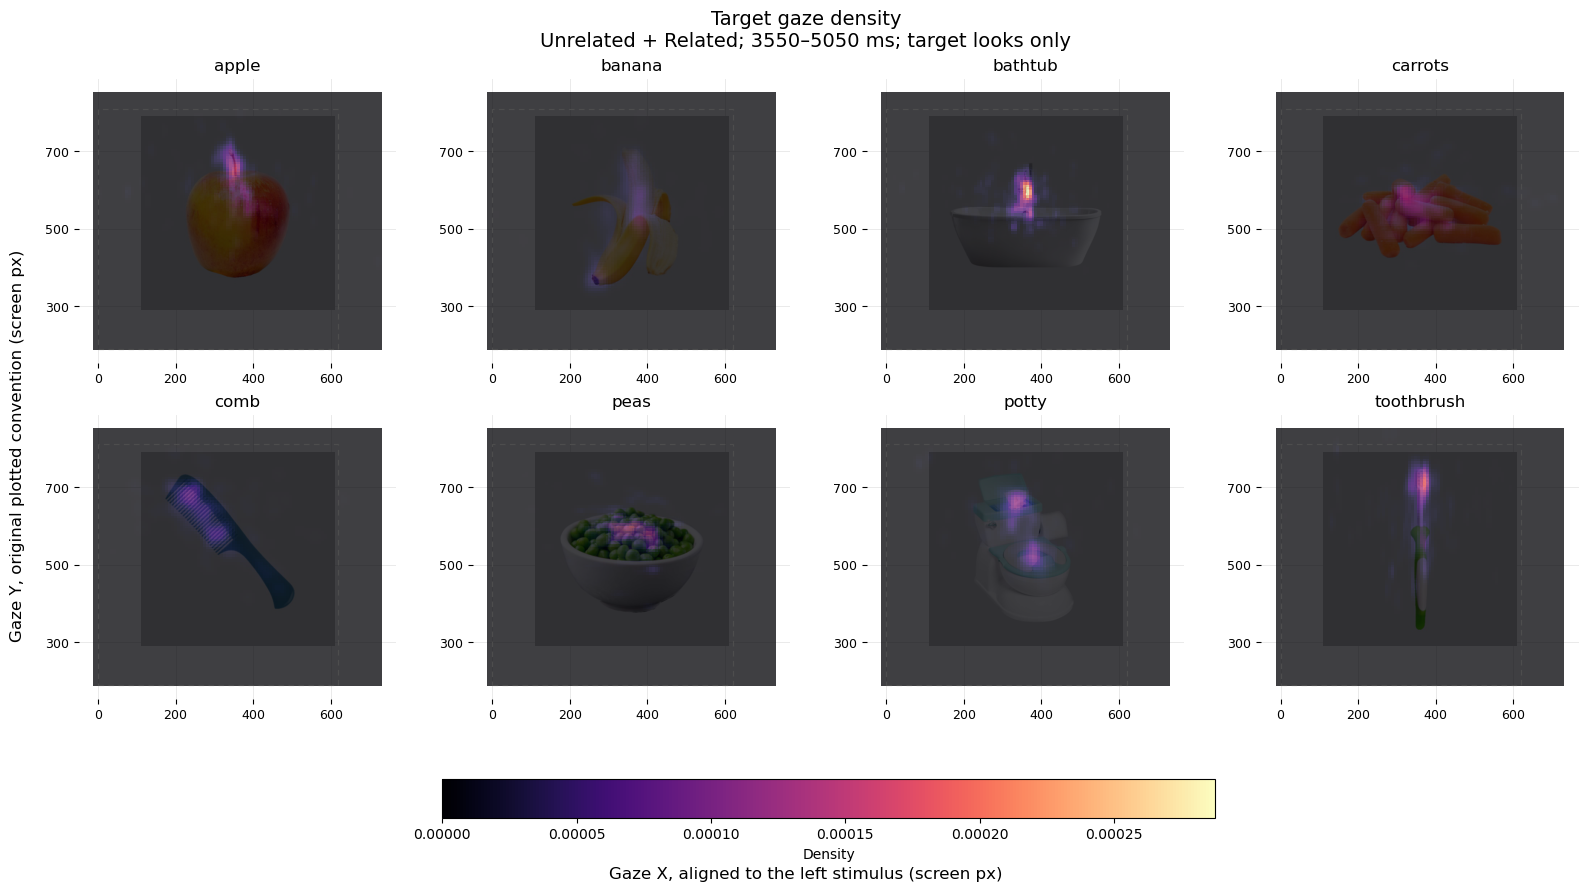

In [6]:
ncols = 4
nrows = (len(target_names) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.4 * nrows),
                         squeeze=False, layout="constrained")
fig.patch.set_alpha(0)
for ax, target in zip(axes.flat, target_names):
    draw_target(ax, target)
for ax in list(axes.flat)[len(target_names):]:
    ax.set_visible(False)
fig.suptitle(f"Target gaze density\n{selection_text}", fontsize=14)
fig.supxlabel("Gaze X, aligned to the left stimulus (screen px)")
fig.supylabel("Gaze Y, original plotted convention (screen px)")
add_density_legend(fig, axes)
save_figure(fig, "gaze_density_overview.png")
plt.show()

## Inspect one target

Change `TARGET_TO_INSPECT` in the settings cell to any listed target and rerun this cell. It uses the overview's exact KDE grid, color scale, and buffer bounds.

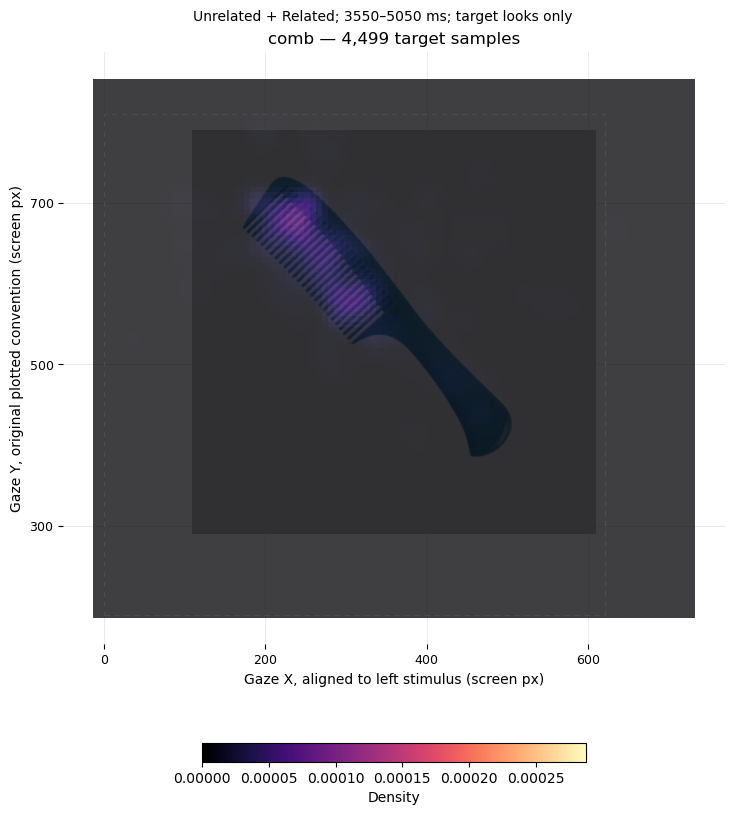

In [7]:
if TARGET_TO_INSPECT not in densities:
    raise ValueError(f"Choose a target with retained samples: {target_names}")
fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")
fig.patch.set_alpha(0)
draw_target(ax, TARGET_TO_INSPECT)
ax.set_title(f"{TARGET_TO_INSPECT} — {gaze_target['TargetImage'].eq(TARGET_TO_INSPECT).sum():,} target samples")
ax.set_xlabel("Gaze X, aligned to left stimulus (screen px)")
ax.set_ylabel("Gaze Y, original plotted convention (screen px)")
fig.suptitle(selection_text, fontsize=10)
add_density_legend(fig, [ax])
plt.show()

## Raw target gaze scatter

This provides an inline check of the retained samples before smoothing. It keeps the same image placement, gaze coordinates, and buffer as the heatmaps.

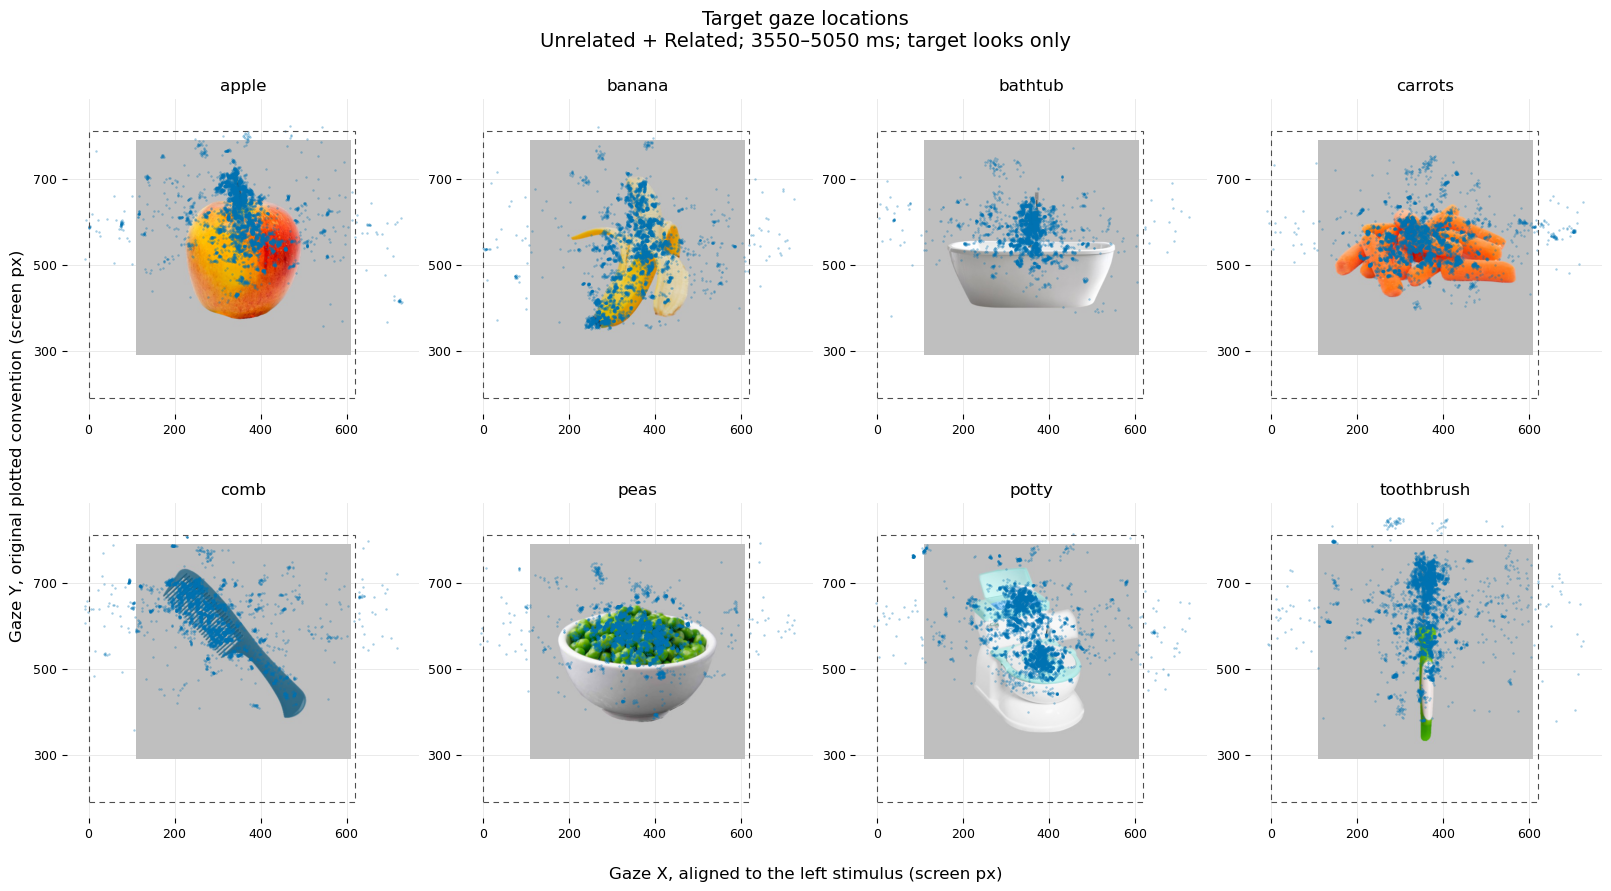

In [8]:
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.4 * nrows),
                         squeeze=False, layout="constrained")
fig.patch.set_alpha(0)
for ax, target in zip(axes.flat, target_names):
    draw_target(ax, target, scatter=True)
for ax in list(axes.flat)[len(target_names):]:
    ax.set_visible(False)
fig.suptitle(f"Target gaze locations\n{selection_text}", fontsize=14)
fig.supxlabel("Gaze X, aligned to the left stimulus (screen px)")
fig.supylabel("Gaze Y, original plotted convention (screen px)")
save_figure(fig, "gaze_scatter_overview.png")
plt.show()

## Individual exports and optional inline panels

With `SAVE_FIGURES=True`, save all target heatmaps under `outputs/python_gaze_inspection/by_target/`. Set `SHOW_EACH_TARGET=True` to also display every one inline. Each panel uses the same density grid and normalization as the overview.

In [9]:
if SAVE_FIGURES or SHOW_EACH_TARGET:
    for target in target_names:
        fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")
        fig.patch.set_alpha(0)
        draw_target(ax, target)
        ax.set_xlabel("Gaze X, aligned to left stimulus (screen px)")
        ax.set_ylabel("Gaze Y, original plotted convention (screen px)")
        fig.suptitle(selection_text, fontsize=10)
        add_density_legend(fig, [ax])
        save_figure(fig, f"by_target/{target}_heatmap.png")
        if SHOW_EACH_TARGET:
            display(fig)
        plt.close(fig)
if SAVE_FIGURES:
    print(f"PNG exports saved to {OUTPUT_DIR.relative_to(REPO_ROOT)}/")

PNG exports saved to outputs/python_gaze_inspection/


## Original R reference

The root PNG is displayed unchanged for visual comparison. It has a transparent background, so border areas can look different with a dark image viewer. The notebook's calculations do not require R or any precomputed R density files.

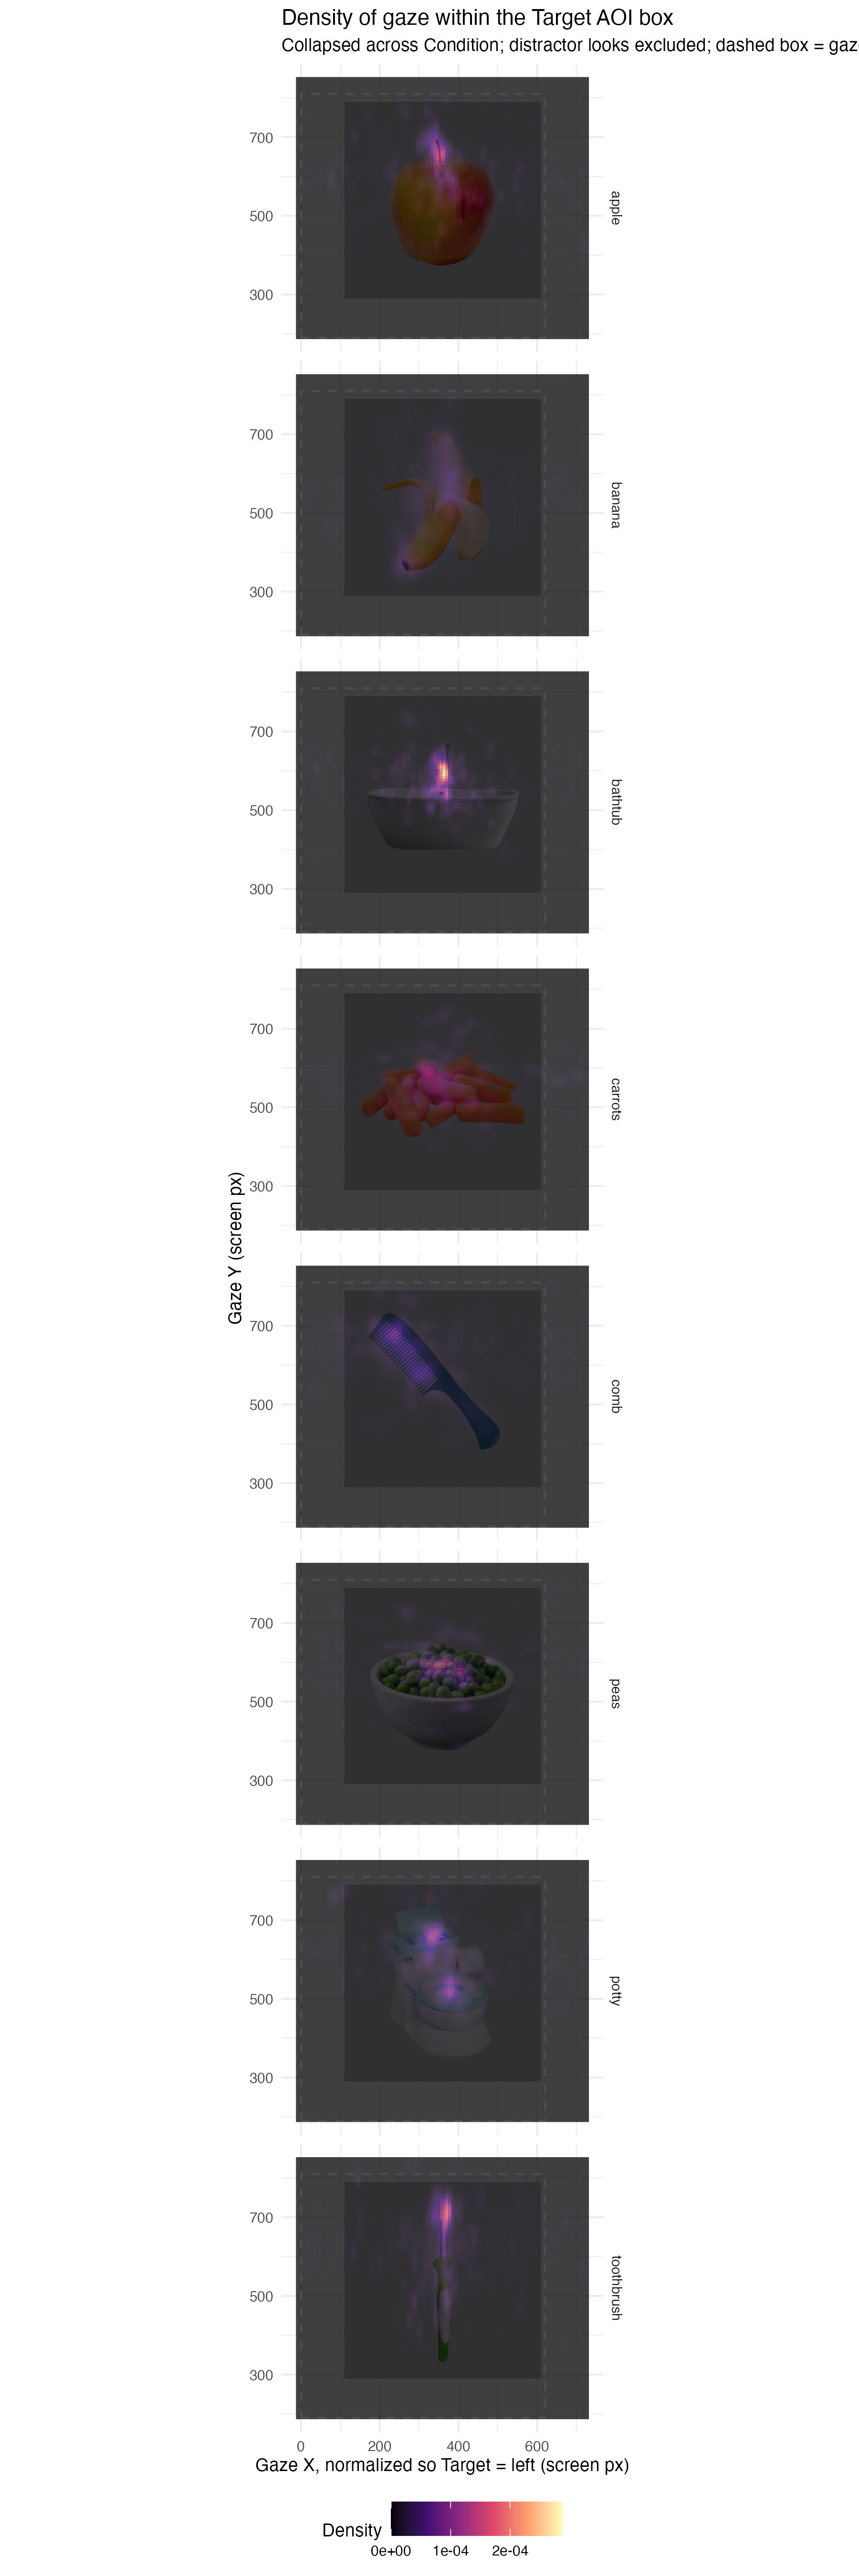

In [10]:
if SHOW_R_REFERENCE:
    reference_path = REPO_ROOT / "gaze_density_by_target.png"
    if reference_path.exists():
        display(DisplayImage(filename=str(reference_path), width=400))
    else:
        print("The optional root reference PNG is not present.")

## Interpretation notes

- The maps pool valid gaze samples across infants and trials; they do not give each infant equal weight.
- Related and unrelated conditions use opposite sides for each target in the supplied data. Condition-specific differences can therefore include side effects.
- The timing window and acquisition geometry reproduce the existing R settings and still require independent verification.
- Keep input CSVs and exported data local. Saved notebook outputs should contain aggregate counts and plots only.